# Week 10: K-Means Clustering

Conducting K-Means Clustering on three different datasets for customer behavior, marketing campaigns, and organizations. Feature scaling, Elbow Plot, Silhouette Scores, and Euclidean distance will be considered in order to decide how many clusters would be suitable for each dataset. In this context, we will try to interpret the clusters generated by analyzing them.

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [22]:
df1 = pd.read_csv("digital_marketing_campaign_dataset.csv")
df2 = pd.read_csv("marketing_and_product_performance.csv")
df3 = pd.read_csv("companies_clean_734.csv")

print("Digital Marketing Campaign:", df1.shape)
print("Marketing and Product Performance:", df2.shape)
print("Synthetic B2B CRM & Marketing:", df3.shape)

Digital Marketing Campaign: (8000, 20)
Marketing and Product Performance: (10000, 17)
Synthetic B2B CRM & Marketing: (734, 19)


## Dataset 1: Digital Marketing Campaign

### Data Preparation and Feature Scaling

The K-means algorithm will apply AdSpend, ClickThroughRate, WebsiteVisits, TimeOnSite, and EmailClicks as features for customer segmentation on the basis of marketing engagement. The K-means algorithm is different from supervised learning algorithms because Conversion will not be used to build the clusters by the algorithm. StandardScaler will scale the features.

In [23]:
features1 = [
    "AdSpend",
    "ClickThroughRate",
    "WebsiteVisits",
    "TimeOnSite",
    "EmailClicks"
]

X1 = df1[features1].copy()

scaler1 = StandardScaler()
X1_scaled = scaler1.fit_transform(X1)

print("Original Feature Summary:")
print(X1.describe().round(2))
print("\nScaled Feature Means:")
print(pd.DataFrame(X1_scaled, columns=features1).mean().round(4))
print("\nScaled Feature Standard Deviations:")
print(pd.DataFrame(X1_scaled, columns=features1).std(ddof=0).round(4))

Original Feature Summary:
       AdSpend  ClickThroughRate  WebsiteVisits  TimeOnSite  EmailClicks
count  8000.00           8000.00        8000.00     8000.00      8000.00
mean   5000.94              0.15          24.75        7.73         4.47
std    2838.04              0.08          14.31        4.23         2.86
min     100.05              0.01           0.00        0.50         0.00
25%    2523.22              0.08          13.00        4.07         2.00
50%    5013.44              0.15          25.00        7.68         4.00
75%    7407.99              0.23          37.00       11.48         7.00
max    9997.91              0.30          49.00       15.00         9.00

Scaled Feature Means:
AdSpend            -0.0
ClickThroughRate    0.0
WebsiteVisits      -0.0
TimeOnSite         -0.0
EmailClicks         0.0
dtype: float64

Scaled Feature Standard Deviations:
AdSpend             1.0
ClickThroughRate    1.0
WebsiteVisits       1.0
TimeOnSite          1.0
EmailClicks         1.0
dt

The original features had their own scales of numbers, where AdSpend had values between 100 and 9,998 while ClickThroughRate had values between 0.01 and 0.30. After using the StandardScaler, all the five features were transformed to have a mean of around zero and standard deviation of one. This ensures that the variable with bigger numbers does not affect the Euclidean distances computations for K-Means.

### Elbow Method

Elbow method will be used to find the ideal number of clusters for Digital Marketing Campaign data set. For k-means algorithm, 1-10 clusters will be tested based on inertia value.

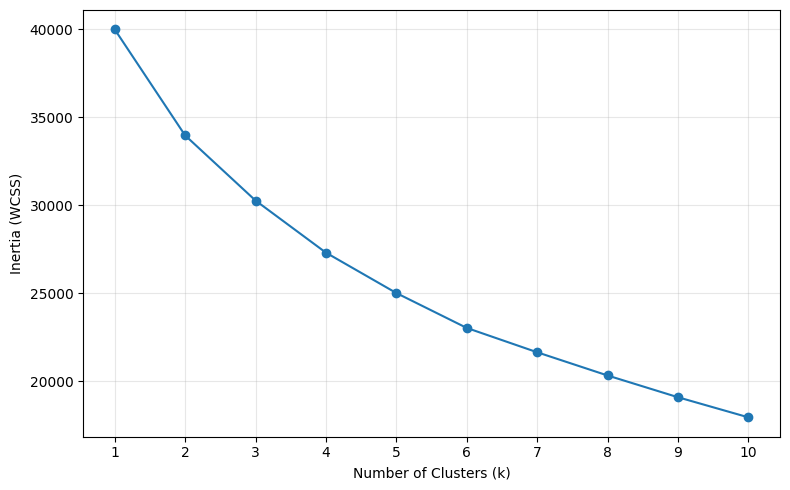

Elbow Method Results:
k=1: 40000.00
k=2: 33972.53
k=3: 30269.35
k=4: 27305.55
k=5: 25009.78
k=6: 23024.81
k=7: 21641.73
k=8: 20321.44
k=9: 19084.29
k=10: 17941.37


In [24]:
k_values1 = range(1, 11)
inertia1 = []

for k in k_values1:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X1_scaled)
    inertia1.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values1, inertia1, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia (WCSS)")
plt.xticks(k_values1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Elbow Method Results:")
for k, inertia in zip(k_values1, inertia1):
    print(f"k={k}: {inertia:.2f}")

Inertia was reduced when more clusters were formed in the elbow method, although an elbow could not be determined. Three or four clusters can be considered adequate; however, silhouette score is required for cluster validation.

### Silhouette Score Analysis

The Silhouette Score will be computed for the K-means algorithm setups using 2 up to 10 clusters. The Silhouette score measures the distance that data points are clustered together inside their respective clusters in comparison to other nearby clusters. In this case, a smaller subset of 2,000 points will be taken as a sample.

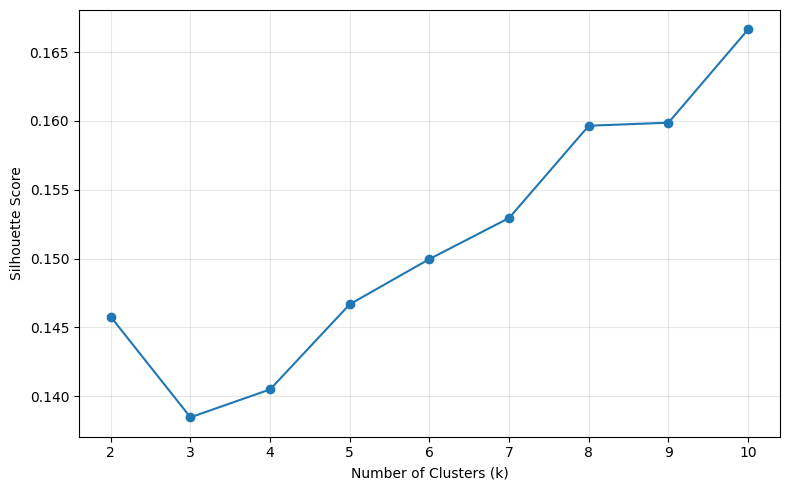

Silhouette Score Results:
k=2: 0.1458
k=3: 0.1385
k=4: 0.1405
k=5: 0.1467
k=6: 0.1500
k=7: 0.1530
k=8: 0.1597
k=9: 0.1599
k=10: 0.1667

Best k: 10


In [25]:
k_values_sil1 = range(2, 11)
silhouette_results1 = []

for k in k_values_sil1:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X1_scaled)
    score = silhouette_score(
        X1_scaled,
        labels,
        sample_size=2000,
        random_state=42
    )

    silhouette_results1.append(score)

plt.figure(figsize=(8, 5))
plt.plot(k_values_sil1, silhouette_results1, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(k_values_sil1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Silhouette Score Results:")
for k, score in zip(k_values_sil1, silhouette_results1):
    print(f"k={k}: {score:.4f}")
print(
    "\nBest k:",
    list(k_values_sil1)[np.argmax(silhouette_results1)]
)

In Silhouette analysis, the number of clusters with the highest score was found to be 10, with an average Silhouette score of 0.1667. However, all Silhouette scores are relatively low, indicating that there is overlap between the clusters of customers. This, together with the lack of an elbow on the plot of inertia versus the number of clusters, shows that there are no distinct clusters in this data set.

### K-Means Clustering

The K-means will have 10 clusters since it uses the highest Silhouette score. It will cluster similar objects while minimizing variations within clusters using Euclidean distance. The low silhouette score indicates that the clusters are customer exploratory segments and not groups.

In [26]:
kmeans1 = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

clusters1 = kmeans1.fit_predict(X1_scaled)
df1_clustered = df1.copy()
df1_clustered["Cluster"] = clusters1

print("Cluster Distribution:")
print(df1_clustered["Cluster"].value_counts().sort_index())
print("\nFinal Model Inertia:")
print(round(kmeans1.inertia_, 2))
print("\nSilhouette Score:")
print(
    round(
        silhouette_score(
            X1_scaled,
            clusters1,
            sample_size=2000,
            random_state=42
        ),
        4
    )
)

Cluster Distribution:
Cluster
0    820
1    804
2    793
3    777
4    818
5    782
6    798
7    783
8    832
9    793
Name: count, dtype: int64

Final Model Inertia:
17941.37

Silhouette Score:
0.1667


The K-Means algorithm has been able to group all 8,000 customers into 10 different groups with group sizes between 777 and 832. Inertia of 17,941.37 and Silhouette score of 0.1667 have been calculated for this model. While the sizes of the groups were not far off each other, the Silhouette score is too low for there not to be overlap between the groups.

### Cluster Characteristics and Conversion Rates

The means of the five clustering variables will be computed per cluster to reveal any disparities in customers' behavior in terms of engagement. The conversion rate will be considered as well to find out if there are any differences between the customer segments in terms of marketing performance._conversion was not included in clustering at all.

In [27]:
cluster_summary1 = df1_clustered.groupby("Cluster")[features1].mean()

cluster_summary1["Customer_Count"] = (
    df1_clustered.groupby("Cluster").size()
)

cluster_summary1["Conversion_Rate"] = (
    df1_clustered.groupby("Cluster")["Conversion"].mean() * 100
)

print("Cluster Characteristics:")
print(cluster_summary1.round(2).to_string())

Cluster Characteristics:
         AdSpend  ClickThroughRate  WebsiteVisits  TimeOnSite  EmailClicks  Customer_Count  Conversion_Rate
Cluster                                                                                                    
0        7807.15              0.24          35.30        5.87         5.10             820            94.51
1        2515.59              0.17          35.57        4.63         1.95             804            79.98
2        6665.39              0.09          35.90       11.01         2.15             793            90.29
3        2649.66              0.19          35.88       11.09         6.82             777            93.56
4        4611.66              0.24          15.71       11.30         2.19             818            90.10
5        5402.15              0.07          35.79        4.37         6.67             782            86.70
6        3120.04              0.21          13.29        4.06         6.65             798            85.96
7  

Cluster analysis showed variations in customer engagement and conversion rates among the 10 clusters. The best cluster in terms of conversion rate was Cluster 0, which recorded 94.51% conversion rate along with the highest average spending on advertisement. Clusters 8 and 3 also recorded good conversion rates as well as customer engagement. On the other hand, Cluster 9 and 1 recorded the least conversion rates at 78.18% and 79.98% respectively. The results imply that certain combinations of customer advertisement exposure, web page visits, and emails yield different results in terms of conversions. However, the low Silhouette score implies that there is an overlapping among the clusters.

### Cluster Visualization Using PCA

For the reduction of five standardized clustering variables into two principal components, Principal Component Analysis (PCA) method will be used. The cluster allocations by the K-means algorithm will be plotted into a scatter plot of two dimensions. PCA method will be used exclusively for visualization purposes and will not affect the initial clustering results. Moreover, the proportion of variance for the first two principal components will be determined.

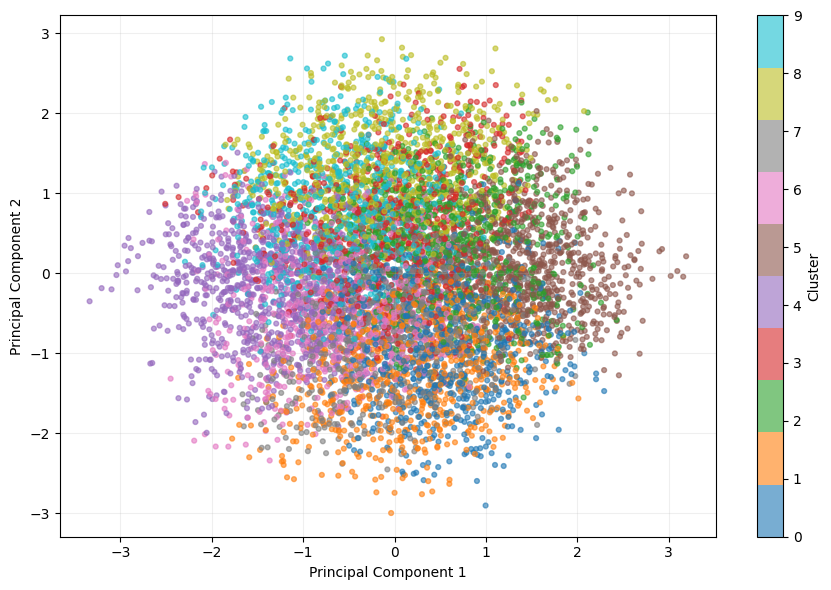

Explained Variance Ratio:
[0.2068 0.2026]

Total Explained Variance: 40.95 %


In [28]:
pca1 = PCA(n_components=2)
X1_pca = pca1.fit_transform(X1_scaled)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X1_pca[:, 0],
    X1_pca[:, 1],
    c=clusters1,
    cmap="tab10",
    s=12,
    alpha=0.6
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Explained Variance Ratio:")
print(pca1.explained_variance_ratio_.round(4))
print(
    "\nTotal Explained Variance:",
    round(pca1.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

The PCA plot revealed a lot of overlap between the 10 customer segments, especially in the center of the graph. The variance covered by the first two principal components was 40.95%, meaning that this visualization reveals only less than half of the information from the original features. This can be seen from the low Silhouette value of 0.1667 and implies that the customer segments are not distinctly separated. However, there may be variations on other criteria which are not depicted on the PCA plot.

### Dataset 1 Conclusion

K-Means Clustering technique was used on the Digital Marketing Campaign dataset based on five standardized variables related to customer engagement. There was no clear result on an optimal number of clusters according to the Elbow method. Nevertheless, according to Silhouette analysis, 10 clusters are the most successful combination and its value is equal to 0.1667. Despite a relatively even distribution of cluster sizes, there is a large Silhouette score and visualization via PCA, which indicates significant overlapping of clusters. The analysis of clusters’ features showed differences in advertising expenses, website activity, email engagement, and conversion rate. Thus, conversion rate varied from 78.18% to 94.51%, so customer engagement may be related to different marketing results. Nevertheless, poor clustering makes these groups non-reliable customer segments.

## Dataset 2: Marketing and Product Performance

### Data Preparation and Feature Scaling

K-means clustering will be performed on the following five features: Budget, Clicks, Conversions, Units Sold, and Bundle Price. This includes variables related to the spending and performance of the campaign, as well as the number of clicks, conversions, and sales of the products. ROI will not be utilized to form the clusters but it will be studied to see if there is any difference between the marketing effectiveness of the different clusters. All five features will be standardized using StandardScaler.

In [29]:
features2 = [
    "Budget",
    "Clicks",
    "Conversions",
    "Units_Sold",
    "Bundle_Price"
]

X2 = df2[features2].copy()
scaler2 = StandardScaler()
X2_scaled = scaler2.fit_transform(X2)

print("Original Feature Summary:")
print(X2.describe().round(2))
print("\nScaled Feature Means:")
print(pd.DataFrame(X2_scaled, columns=features2).mean().round(4))
print("\nScaled Feature Standard Deviations:")
print(pd.DataFrame(X2_scaled, columns=features2).std(ddof=0).round(4))

Original Feature Summary:
         Budget    Clicks  Conversions  Units_Sold  Bundle_Price
count  10000.00  10000.00     10000.00    10000.00      10000.00
mean   25263.61   2481.90       498.98      100.69        275.20
std    14350.09   1435.97       289.48       57.07        129.22
min      500.44     10.00         1.00        1.00         50.01
25%    12789.19   1225.75       247.00       52.00        165.72
50%    25030.17   2451.00       499.00      101.00        272.56
75%    37921.73   3723.00       751.00      150.00        387.32
max    49999.63   4999.00       999.00      199.00        499.97

Scaled Feature Means:
Budget         -0.0
Clicks         -0.0
Conversions    -0.0
Units_Sold      0.0
Bundle_Price   -0.0
dtype: float64

Scaled Feature Standard Deviations:
Budget          1.0
Clicks          1.0
Conversions     1.0
Units_Sold      1.0
Bundle_Price    1.0
dtype: float64


The initial features had varying numeric scales, where Budget had a scale of about 500-50,000 and Bundle_Price having a scale of 50-500. However, after using StandardScaler, the five features had an average close to 0 and standard deviation of 1. This ensures that no variable with a high numeric value dominates the calculation of the Euclidean distances.

### Elbow Method

Elbow technique will be employed to determine the optimal number of clusters for the Marketing and Product Performance data set. K-means clustering will be run on 1 through 10 numbers of clusters, and the within-cluster sum of squares (inertia) will be determined for each. A significant knee on the inertia plot might suggest an optimal number of clusters where the addition of further clusters provides only marginal gains to clustering effectiveness.

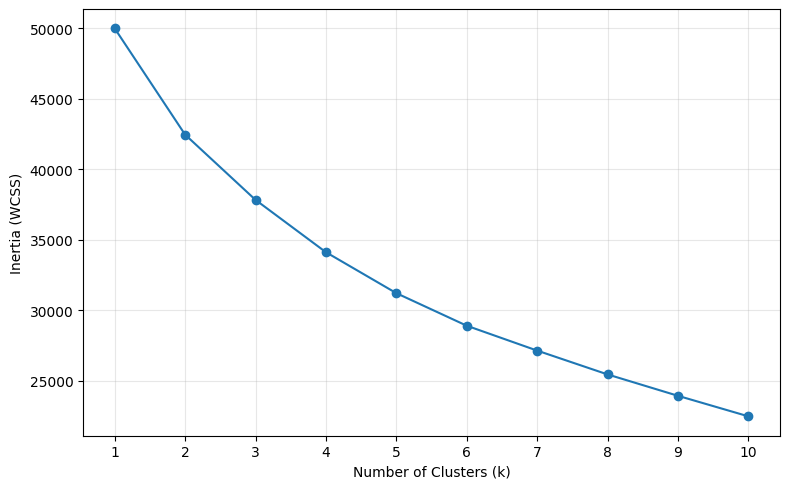

Elbow Method Results:
k=1: 50000.00
k=2: 42457.33
k=3: 37826.33
k=4: 34111.39
k=5: 31204.99
k=6: 28892.91
k=7: 27127.29
k=8: 25435.95
k=9: 23917.40
k=10: 22459.96


In [30]:
k_values2 = range(1, 11)
inertia2 = []

for k in k_values2:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X2_scaled)
    inertia2.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values2, inertia2, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia (WCSS)")
plt.xticks(k_values2)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("Elbow Method Results:")
for k, inertia in zip(k_values2, inertia2):
    print(f"k={k}: {inertia:.2f}")

According to the elbow approach, the value of inertia fell from 50,000.00 in the case of one cluster to 22,459.96 in the case of ten clusters. The maximum improvement was noted when the number of clusters was increased from one to two, then followed by gradual improvement when more clusters were added. Nevertheless, no clear elbow could be noticed in the graph, implying that there was no optimal number of clusters.

### Silhouette Score Analysis

Scores for Silhouette would be computed for K-Means clusterings from 2 to 10 clusters. Silhouette measures how similar objects are to their own group versus other clusters. The greater the score is, the better. Scores around zero show that groups overlap. For performance purposes, we would sample only 2000 objects.

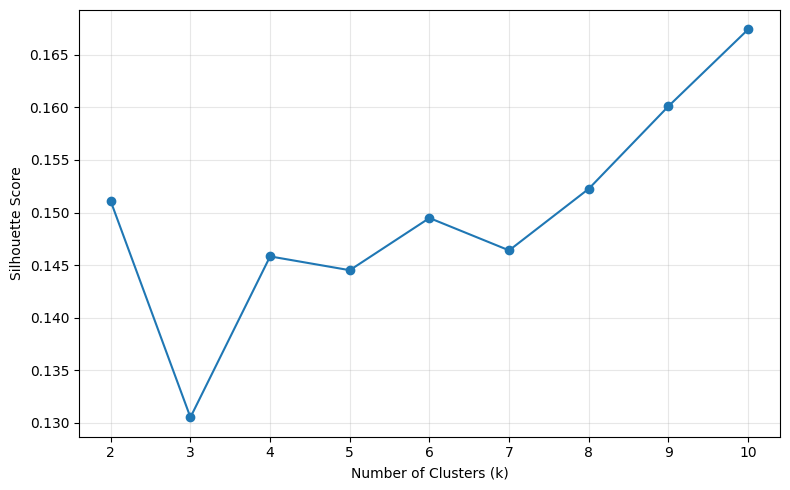

Silhouette Score Results:
k=2: 0.1511
k=3: 0.1305
k=4: 0.1458
k=5: 0.1445
k=6: 0.1495
k=7: 0.1464
k=8: 0.1523
k=9: 0.1601
k=10: 0.1674

Best k: 10


In [31]:
k_values_sil2 = range(2, 11)
silhouette_results2 = []

for k in k_values_sil2:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(X2_scaled)
    score = silhouette_score(
        X2_scaled,
        labels,
        sample_size=2000,
        random_state=42
    )
    silhouette_results2.append(score)

plt.figure(figsize=(8, 5))
plt.plot(k_values_sil2, silhouette_results2, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(k_values_sil2)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Silhouette Score Results:")
for k, score in zip(k_values_sil2, silhouette_results2):
    print(f"k={k}: {score:.4f}")
print(
    "\nBest k:",
    list(k_values_sil2)[np.argmax(silhouette_results2)]
)

The number of clusters giving the maximum score was found to be 10, with the score value being 0.1674. It should also be noted that Silhouette scores were relatively low in general, indicating high overlap between the groups. In combination with the lack of an elbow on the plot of inertia, this implies the absence of strongly separated clusters within the data set.

### K-Means Clustering

K-Means clustering will have 10 clusters owing to the high Silhouette score obtained from the various configurations evaluated. The use of Euclidean distance is applied to cluster the campaigns to their closest cluster centers in order to minimize the squared distances. Since the Silhouette scores were quite low, the clusters obtained will be considered exploratory groupings of the campaigns.

In [32]:
kmeans2 = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

clusters2 = kmeans2.fit_predict(X2_scaled)
df2_clustered = df2.copy()
df2_clustered["Cluster"] = clusters2

print("Cluster Distribution:")
print(df2_clustered["Cluster"].value_counts().sort_index())
print("\nFinal Model Inertia:")
print(round(kmeans2.inertia_, 2))
print("\nSilhouette Score:")
print(round(silhouette_score(X2_scaled, clusters2, sample_size=2000, random_state=42), 4))

Cluster Distribution:
Cluster
0     987
1    1018
2    1006
3     896
4    1066
5    1022
6    1064
7    1021
8     955
9     965
Name: count, dtype: int64

Final Model Inertia:
22459.96

Silhouette Score:
0.1674


All 10,000 marketing campaigns have been accurately clustered by the K-Means algorithm into 10 clusters, with each cluster containing between 896 and 1,066 samples. Inertia for the model is 22,459.96, while the Silhouette score is 0.1674. Despite the clusters being relatively balanced in terms of size, their high Silhouette score implies that there is a lot of overlapping between the clusters.

### Cluster Characteristics and ROI

The averages of the five features of clustering will be taken for each group to detect the differences in campaign spend, engagement, conversions, products sold, and pricing. The average return on investment and the proportion of campaigns with returns that exceed the median return on investment will be evaluated to establish the difference in the marketing effectiveness between the identified clusters. The ROI was not used for clustering purposes.

In [33]:
cluster_summary2 = df2_clustered.groupby("Cluster")[features2].mean()
cluster_summary2["Campaign_Count"] = (df2_clustered.groupby("Cluster").size())
cluster_summary2["Average_ROI"] = (df2_clustered.groupby("Cluster")["ROI"].mean())

cluster_summary2["High_ROI_Rate"] = (df2_clustered.groupby("Cluster")["ROI"]
    .apply(lambda x: (x > df2["ROI"].median()).mean() * 100)
)
print("Cluster Characteristics:")
print(cluster_summary2.round(2).to_string())

Cluster Characteristics:
           Budget   Clicks  Conversions  Units_Sold  Bundle_Price  Campaign_Count  Average_ROI  High_ROI_Rate
Cluster                                                                                                      
0        15325.02  1342.36       252.84      146.59        327.26             987         2.75          49.54
1        37251.32  3602.51       732.11       56.23        234.90            1018         2.75          50.49
2        35034.16  1255.88       721.82      146.35        197.93            1006         2.74          50.10
3        20182.09  3269.05       739.18      145.54        412.58             896         2.78          49.89
4        37342.53  3684.47       262.89      146.30        279.96            1066         2.80          51.50
5        12441.88  3520.29       637.51      132.82        147.35            1022         2.76          49.71
6        28412.96  1563.96       249.48       61.69        144.27            1064         2.74 

Variation in expenditure on campaigns, number of clicks, conversions, products sold, and price of products. The average ROI for all ten clusters was nearly constant, between 2.69 and 2.80. Cluster 4 performed best, with the highest share of campaigns exceeding median ROI, which is 51.50%, and Cluster 6 performed worst, with the lowest share of campaigns exceeding median ROI at 48.50%. The differences are very small, indicating that the marketing and sales variables are not powerful differentiators of the campaigns based on profit.

### Cluster Visualization Using PCA

Principal Component Analysis (PCA) will reduce the five standardized attributes of the campaign into two principal components. The already formed clusters using K-means will then be plotted using a two-dimensional scatter plot. The principal component analysis (PCA) is used solely for visualization purposes and does not affect the clusters. The percentage of variance of the two principal components will also be determined.

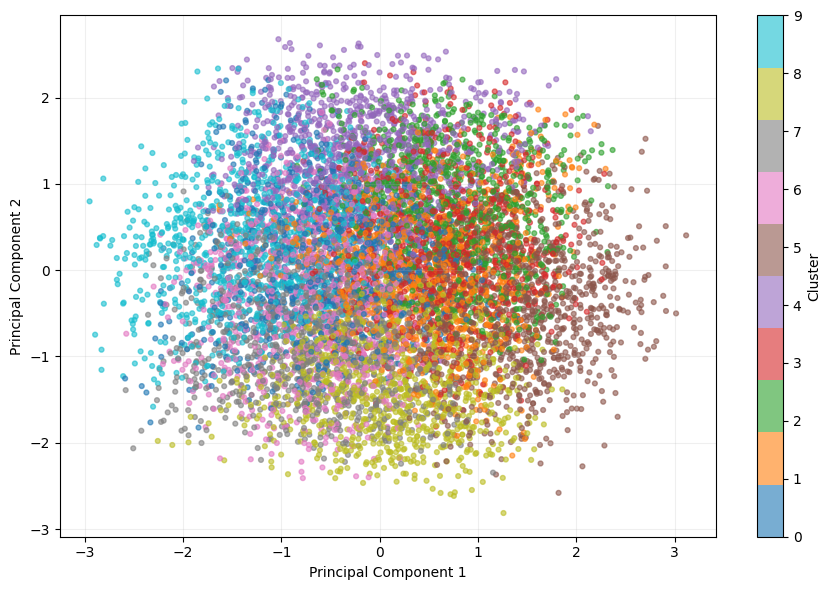

Explained Variance Ratio:
[0.2076 0.2031]

Total Explained Variance: 41.07 %


In [34]:
pca2 = PCA(n_components=2)
X2_pca = pca2.fit_transform(X2_scaled)
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X2_pca[:, 0],
    X2_pca[:, 1],
    c=clusters2,
    cmap="tab10",
    s=12,
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print("Explained Variance Ratio:")
print(pca2.explained_variance_ratio_.round(4))
print("\nTotal Explained Variance:", round(pca2.explained_variance_ratio_.sum() * 100, 2), "%")

The PCA analysis revealed significant overlap between the 10 marketing campaign clusters, especially in the central part of the chart. The first two principal components capture 41.07% of the overall variability, which means that the two-dimensional analysis reveals only less than half of the information provided by the initial data. This is confirmed by the low value of the Silhouette score, which equals 0.1674 and indicates the weak clustering of the campaigns. Still, some variations may be observed in dimensions not reflected by the chart.

### Dataset 2 Conclusion

K-Means clustering has been applied to study the Marketing and Product Performance dataset by using five normalized variables associated with the marketing and sales process. As far as the optimum number of clusters is concerned, there is no particular indication by using elbow and silhouette methods. Nevertheless, the Silhouette method has shown 10 clusters with the maximum Silhouette score which is equal to 0.1674. It may be observed that the numbers of clusters are evenly distributed, but overlapping of the clusters may be concluded from the low Silhouette score and PCA graph. The clusters have displayed certain differences in terms of campaign budget, clicks, conversions, unit sold and price of the product. On the other hand, the ROI has remained more or less constant which is around 2.69 to 2.80 while 50% of campaigns have ROI greater than the median value.

## Dataset 3: Synthetic B2B CRM & Marketing

### Data Preparation and Feature Scaling

The K-means clustering technique will be performed on four numeric variables: Annual_Revenue (M₺), Marketing_Spend (K₺), Days_Since_Last_Purchase, and Total_Purchases_Last_Year. The mentioned variables show information about revenue, spending on marketing, and purchases of companies. Contract_Status will not be considered while performing the K-means, however, the information about it will be analyzed later on to see if there are any differences between the companies in active contracts. The variables will be standardized using the StandardScaler method to avoid domination of large numeric values in the distance calculation.

In [35]:
features3 = [
    "Annual_Revenue (M₺)",
    "Marketing_Spend (K₺)",
    "Days_Since_Last_Purchase",
    "Total_Purchases_Last_Year"
]

X3 = df3[features3].copy()
scaler3 = StandardScaler()
X3_scaled = scaler3.fit_transform(X3)

print("Original Feature Summary:")
print(X3.describe().round(2))
print("\nScaled Feature Means:")
print(pd.DataFrame(X3_scaled, columns=features3).mean().round(4))
print("\nScaled Feature Standard Deviations:")
print(pd.DataFrame(X3_scaled, columns=features3).std(ddof=0).round(4))

Original Feature Summary:
       Annual_Revenue (M₺)  Marketing_Spend (K₺)  Days_Since_Last_Purchase  \
count               734.00                734.00                    734.00   
mean                 18.33                 21.28                    102.54   
std                  32.29                 10.14                    109.98   
min                   1.00                  5.00                      5.00   
25%                   3.90                 13.00                     21.00   
50%                   7.10                 20.00                     68.00   
75%                  15.28                 28.00                    154.00   
max                 199.40                 50.00                    448.00   

       Total_Purchases_Last_Year  
count                     734.00  
mean                        6.63  
std                         4.68  
min                         0.00  
25%                         2.00  
50%                         5.00  
75%                       

The original attributes possessed dissimilar numeric scales where annual revenue was between 1.00 and 199.40 million ₺ while days since last purchase was from 5 to 448. Additionally, the annual revenue was positively skewed because its mean was significantly larger than its median. As a result of using StandardScaler, the means of all four attributes were approximately equal to zero while their standard deviations equaled one. This enables the attributes to play equal roles in computing Euclidean distances.

### Elbow Method

Determining the correct number of clusters for the Synthetic B2B CRM & Marketing data set. K-Means clustering will be performed for cluster numbers that range from 1 to 10, and the inertia value will be determined for each. There might be a bend point in the graph of inertia versus the number of clusters, and it could indicate an ideal number of clusters.

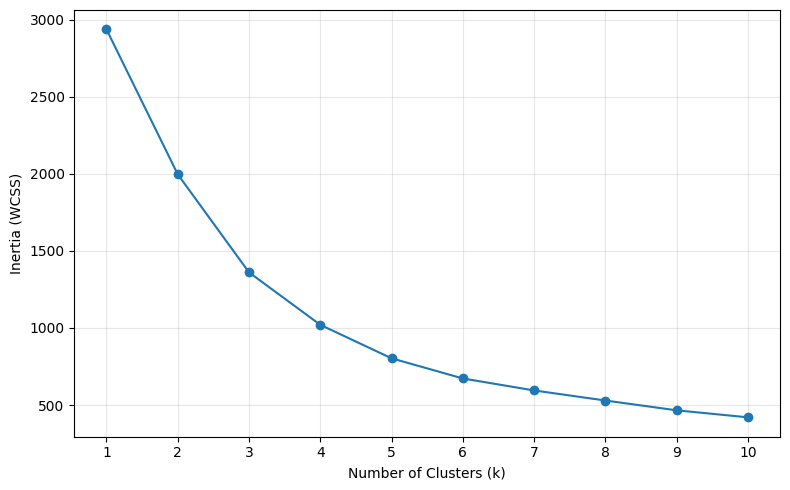

Elbow Method Results:
k=1: 2936.00
k=2: 1996.18
k=3: 1360.26
k=4: 1020.18
k=5: 803.01
k=6: 672.29
k=7: 594.62
k=8: 529.31
k=9: 465.72
k=10: 420.32


In [36]:
k_values3 = range(1, 11)
inertia3 = []

for k in k_values3:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X3_scaled)
    inertia3.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values3, inertia3, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia (WCSS)")
plt.xticks(k_values3)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Elbow Method Results:")
for k, inertia in zip(k_values3, inertia3):
    print(f"k={k}: {inertia:.2f}")

Inertia was found to reduce from 2,936.00 at one cluster to 420.32 at ten clusters. The greatest decrease was seen between one and four clusters, with the curve starting to level off from four or five clusters. In contrast to the former two data sets, this curve showed an obvious elbow point, implying that four or five clusters might be a fair trade-off between minimizing within-cluster variability and excessive complexity. Cluster separation will be analyzed using silhouette analysis.

### Silhouette Score Analysis

Determined for K-Means setups varying between 2 and 10 clusters. Silhouette Score measures how well companies group within their designated clusters relative to the other nearby clusters. High scores mean better clustering, while low scores close to zero mean overlapping clusters. As there are 734 data points in the data set, the entire data set will be used to determine the Silhouette scores.

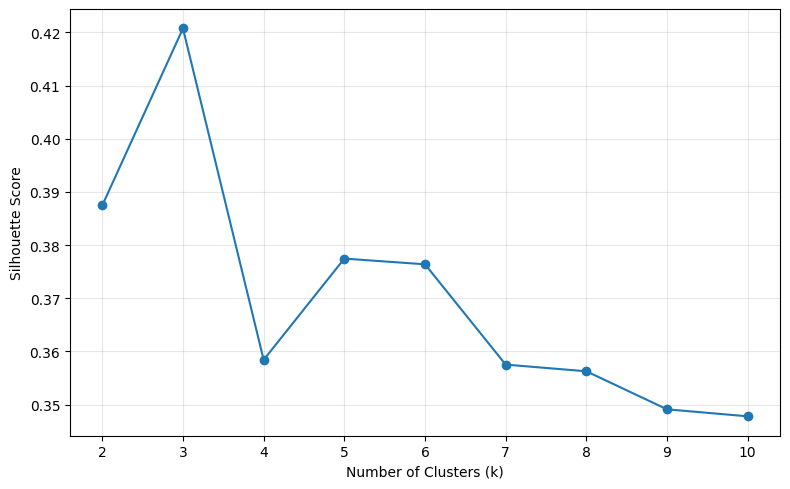

Silhouette Score Results:
k=2: 0.3875
k=3: 0.4208
k=4: 0.3584
k=5: 0.3775
k=6: 0.3764
k=7: 0.3575
k=8: 0.3563
k=9: 0.3491
k=10: 0.3478

Best k: 3


In [37]:
k_values_sil3 = range(2, 11)
silhouette_results3 = []

for k in k_values_sil3:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(X3_scaled)
    score = silhouette_score(X3_scaled, labels)
    silhouette_results3.append(score)

plt.figure(figsize=(8, 5))
plt.plot(k_values_sil3, silhouette_results3, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(k_values_sil3)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Silhouette Score Results:")
for k, score in zip(k_values_sil3, silhouette_results3):
    print(f"k={k}: {score:.4f}")
print(
    "\nBest k:",
    list(k_values_sil3)[np.argmax(silhouette_results3)]
)

Clusters were set at 3, which gave us a score of 0.4208. It means that we have quite distinct groups of companies and is much more successful than the clustering results obtained from the previous datasets. In accordance with the elbow chart, the number of clusters is about 4-5, but the Silhouette score shows that the preferable number of clusters is 3, which means that different clustering techniques can give different results.

### K-Means Clustering

Using 3 clusters based on the highest Silhouette score obtained from the various combinations tried out. The method makes use of Euclidean distance to classify firms depending on similarities in their revenues, marketing expenditure, and purchasing patterns. We shall analyze the results to test the clustering combination.

In [38]:
kmeans3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters3 = kmeans3.fit_predict(X3_scaled)
df3_clustered = df3.copy()
df3_clustered["Cluster"] = clusters3

print("Cluster Distribution:")
print(df3_clustered["Cluster"].value_counts().sort_index())
print("\nFinal Model Inertia:")
print(round(kmeans3.inertia_, 2))
print("\nSilhouette Score:")
print(round(silhouette_score(X3_scaled, clusters3), 4))

Cluster Distribution:
Cluster
0    177
1    514
2     43
Name: count, dtype: int64

Final Model Inertia:
1360.26

Silhouette Score:
0.4208


The K-Means algorithm was able to classify all 734 firms into three clusters; there were 177 firms in Cluster 0, 514 firms in Cluster 1, and 43 firms in Cluster 2. The inertia and Silhouette score obtained for this dataset were 1,360.26 and 0.4208, respectively, showing better separation among the clusters compared to the two previous datasets. In contrast to Datasets 1 and 2, the number of elements in each cluster was not equal, which means that the firms have some unique features forming different-sized clusters.

### Cluster Characteristics and Contract Status

The means of the four clustering variables will be computed in order to discover whether there are any differences between the clusters in terms of firm revenue, marketing budgets, recency of purchases, and frequency of purchases. It will be determined if there are any differences between the clusters in terms of whether they have active contracts or not. Contract_Status is not included in the clustering procedure.

In [39]:
cluster_summary3 = df3_clustered.groupby("Cluster")[features3].mean()
cluster_summary3["Company_Count"] = (df3_clustered.groupby("Cluster").size())
cluster_summary3["Active_Contract_Rate"] = (df3_clustered.groupby("Cluster")["Contract_Status"]
    .apply(lambda x: (x == "Active").mean() * 100)
)
print("Cluster Characteristics:")
print(cluster_summary3.round(2).to_string())

Cluster Characteristics:
         Annual_Revenue (M₺)  Marketing_Spend (K₺)  Days_Since_Last_Purchase  Total_Purchases_Last_Year  Company_Count  Active_Contract_Rate
Cluster                                                                                                                                     
0                      10.80                 20.53                    269.22                       1.31            177                 72.88
1                      11.32                 20.10                     43.59                       8.48            514                 71.21
2                     133.11                 38.42                    121.19                       6.47             43                 76.74


There were three separate company clusters in terms of the results of the cluster analysis. The first cluster (Cluster 0) was made up of the infrequent buyers, whose average time since the last purchase was 269 days and number of purchases was 1.31 per year. The second cluster (Cluster 1) was made up of frequent buyers with an average of 8.48 purchases and 43.59 days since the last purchase. The third cluster (Cluster 2) was formed by high revenue companies with an average revenue of 133.11 million ₺ and marketing expenditures of 38.42 thousand ₺. However, active contract rates were still quite alike with each other between 71.21% to 76.74%.

### Cluster Visualization Using PCA

PCA shall be used to transform four standardized company variables into two principal components for graphing purposes. The currently assigned clusters through K-Means clustering algorithm will be plotted using a two-dimensional scatter plot. PCA is only used for visualizing purposes and will not affect the clustering process in any way. The amount of variability accounted for by the first two principal components will be computed as well.

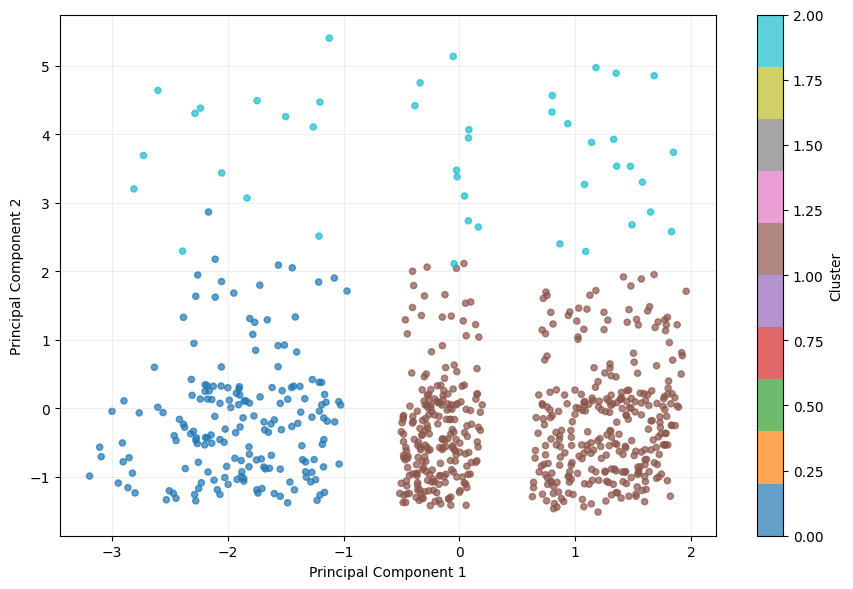

Explained Variance Ratio:
[0.4412 0.3854]

Total Explained Variance: 82.66 %


In [40]:
pca3 = PCA(n_components=2)
X3_pca = pca3.fit_transform(X3_scaled)
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X3_pca[:, 0],
    X3_pca[:, 1],
    c=clusters3,
    cmap="tab10",
    s=20,
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Explained Variance Ratio:")
print(pca3.explained_variance_ratio_.round(4))
print("\nTotal Explained Variance:", round(pca3.explained_variance_ratio_.sum() * 100, 2), "%")

PCA visualization depicted three company clusters that had less overlap compared to the previous two datasets. The first two components accounted for 82.66% of the total variance, meaning that the visualization depicted much of the information present in the four standardized variables. Infrequent buyers were assigned to cluster 0, while frequent buyers belonged to cluster 1 and the high revenue generating companies were placed in cluster 2. The above findings explain why the silhouette score was 0.4208.

### Dataset 3 Conclusion

Based on four standard company characteristics, the elbow method recommended approximately four or five clusters, whereas the Silhouette analysis revealed that there are three clusters with the maximum silhouette value of 0.4208. The variance represented by the PCA plot was 82.66%, which was higher compared to the other two data sets. The analysis revealed three types of company profiles, namely infrequent buyers, frequent buyers, and high revenue companies. There is quite a difference between these three segments in terms of the purchasing frequency, recency of purchases, annual revenue, and marketing expenditure. Nevertheless, the active contract rate does not differ much among these groups, which is between 71.21% and 76.74%.

## Overall Week 10 Conclusion

K-Means algorithm was used on three marketing data sets by standardizing the features, where elbow and Silhouette values were taken into consideration while choosing the clusters. Digital Marketing Campaign and Marketing and Product Performance data sets exhibited poor clustering with Silhouette values of 0.1667 and 0.1674, respectively.

On the other hand, the data set of Synthetic B2B CRM & Marketing demonstrated better Silhouette value of 0.4208 with three clusters. The variance explained by PCA is 82.66%, which indicated the presence of different company profiles. In all, the K-Means algorithm performed well for B2B customers, even though the clusters were not consistent with conversion/ROI/contract.